In [3]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:

import os

BASE = "/content/drive/MyDrive/simuteh-2330511091"

print("Folder proyek ditemukan:", os.path.exists(BASE))
print("\nIsi folder proyek:")

for item in sorted(os.listdir(BASE)):
    print("-", item)


Folder proyek ditemukan: True

Isi folder proyek:
- .git
- .gitignore
- README.md
- data
- hasil
- laporan
- notebook
- requirements.txt
- src


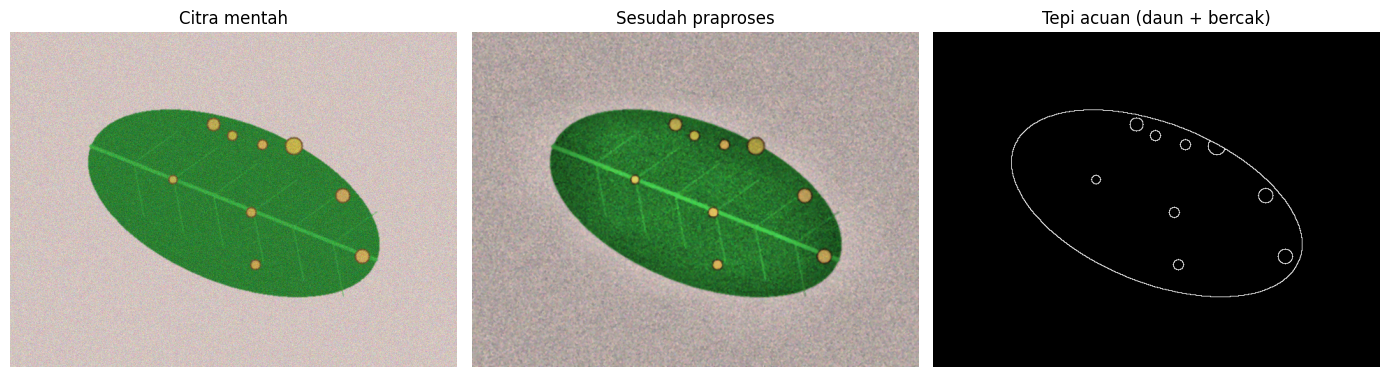

In [6]:
import sys
import os
import json

# Berpindah ke folder proyek agar path relatif (seperti '../src' atau '../data') berfungsi dengan benar
BASE = "/content/drive/MyDrive/simuteh-2330511091"
os.chdir(BASE)

# Menambahkan folder src (yang berada di dalam BASE) ke sys.path
sys.path.append("src")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

with open("hasil/param_praproses.json") as f:
    PARAM = json.load(f)  # hasil Evaluasi P1-P4

label = pd.read_csv("data/sintetis/label.csv")

def muat(nama):
    img = baca(f"data/sintetis/citra/{nama}")
    md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 654.5


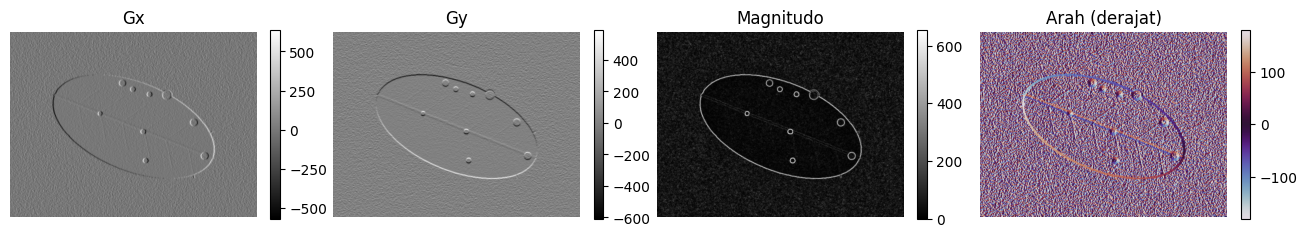

In [7]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah,
"Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else
"gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

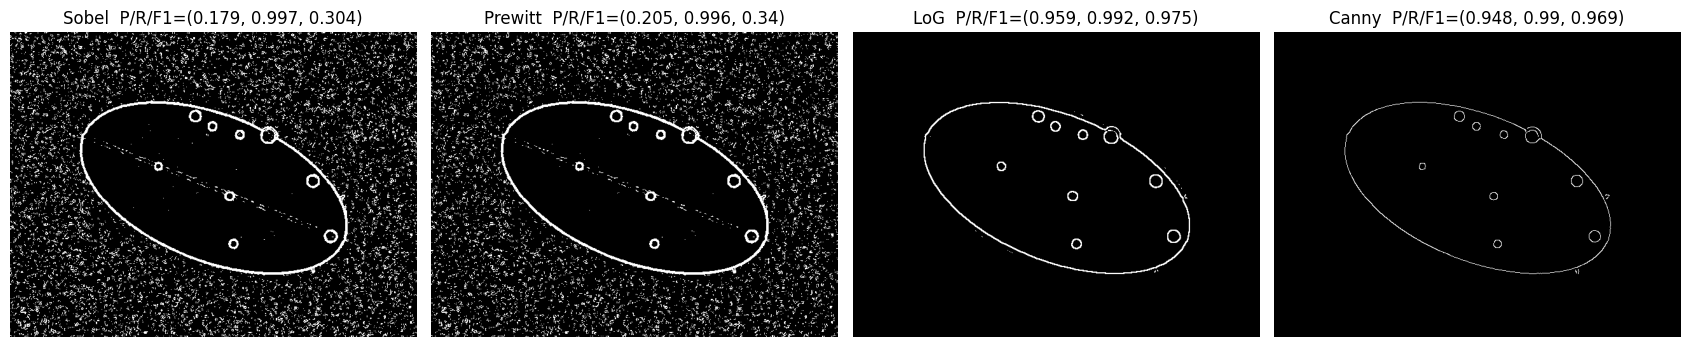

In [8]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
       ukuran=(17, 3.6))

In [11]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))

    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)

print(ringkas)
tabel_tepi.to_csv("hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.818  0.798  0.806
                LoG      0.637  0.998  0.769
                Prewitt  0.779  0.974  0.857
                Sobel    0.742  0.979  0.831
          R     Canny    0.989  0.977  0.982
                LoG      0.886  0.999  0.924
                Prewitt  0.528  0.997  0.637
                Sobel    0.462  0.998  0.575
praproses Gray  Canny    0.692  0.955  0.794
                LoG      0.547  0.998  0.696
                Prewitt  0.533  0.999  0.682
                Sobel    0.499  0.999  0.649
          R     Canny    0.971  0.993  0.981
                LoG      0.836  0.999  0.895
                Prewitt  0.438  0.999  0.571
                Sobel    0.393  0.999  0.525


In [12]:
ringkas = (
    tabel_tepi
    .groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]]
    .mean()
    .round(3)
    .reset_index()
)

display(ringkas)

ringkas.to_csv(
    "../hasil/p5_ringkasan_tepi.csv",
    index=False
)

print("Ringkasan berhasil disimpan!")

,sumber,kanal,metode,P,R,F1
0,mentah,Gray,Canny,0.818,0.798,0.806
1,mentah,Gray,LoG,0.637,0.998,0.769
2,mentah,Gray,Prewitt,0.779,0.974,0.857
3,mentah,Gray,Sobel,0.742,0.979,0.831
4,mentah,R,Canny,0.989,0.977,0.982
5,mentah,R,LoG,0.886,0.999,0.924
6,mentah,R,Prewitt,0.528,0.997,0.637
7,mentah,R,Sobel,0.462,0.998,0.575
8,praproses,Gray,Canny,0.692,0.955,0.794
9,praproses,Gray,LoG,0.547,0.998,0.696


Ringkasan berhasil disimpan!


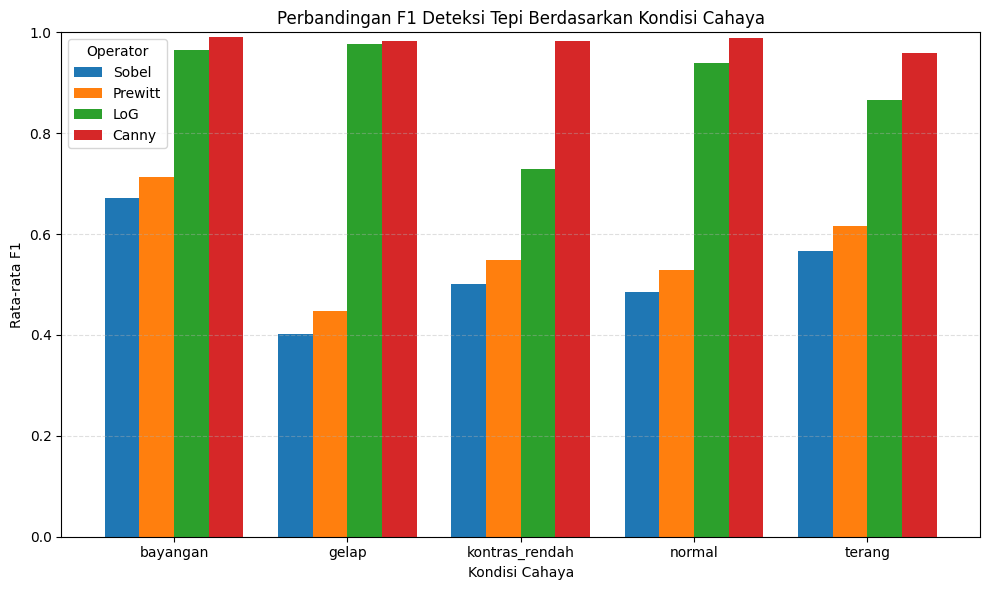

Grafik berhasil disimpan di hasil/p5_f1_kondisi.png


In [17]:

# Langkah 1.5 - Grafik F1 berdasarkan kondisi cahaya

import matplotlib.pyplot as plt

# Ambil data kanal R setelah praproses
data_grafik = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Hitung rata-rata F1 setiap kondisi cahaya dan operator
grafik = data_grafik.pivot_table(
    index="kondisi",
    columns="metode",
    values="F1",
    aggfunc="mean"
).reindex(columns=["Sobel", "Prewitt", "LoG", "Canny"])

# Buat grafik batang
grafik.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Perbandingan F1 Deteksi Tepi Berdasarkan Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Rata-rata F1")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Operator")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Simpan grafik
plt.savefig("hasil/p5_f1_kondisi.png", dpi=300, bbox_inches="tight")
plt.show()

print("Grafik berhasil disimpan di hasil/p5_f1_kondisi.png")


In [15]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)

    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])

print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.489  0.996  0.593     0.983
      30/90    0.019  0.998  0.038     0.992
      50/150   0.114  0.997  0.170     0.986
1.0   100/200  0.982  0.995  0.989     0.977
      30/90    0.219  0.996  0.309     0.980
      50/150   0.886  0.996  0.934     0.978
2.0   100/200  0.819  0.807  0.812     0.738
      30/90    0.971  0.993  0.981     0.965
      50/150   0.988  0.988  0.987     0.948
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.985   0.981
      30/90    0.996   0.988
      50/150   0.989   0.983
1.0   100/200  0.982   0.971
      30/90    0.987   0.973
      50/150   0.984   0.972
2.0   100/200  0.775   0.701
      30/90    0.970   0.960
      50/150   0.948   0.948


In [16]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x
median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1",
"median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi",
values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.544  0.529           0.683   0.729   0.862
      tetap 30/90     0.788  0.740           0.937   0.753   0.753
R     otomatis        0.488  0.376           0.572   0.727   0.956
      tetap 30/90     0.990  0.983           0.983   0.988   0.959
kanal  kondisi       
Gray   bayangan          118.1
       gelap             134.5
       kontras_rendah    147.4
       normal            169.8
       terang            195.4
R      bayangan          121.1
       gelap             145.6
       kontras_rendah    150.5
       normal            176.2
       terang            200.2
Name: median, dtype: float64


In [18]:

def canny_persentil(g, q=95, rasio=0.4, sigma=2.0):
    """Canny dengan ambang otomatis berdasarkan persentil magnitudo gradien."""
    halus = cv2.GaussianBlur(
        g.astype(np.uint8), (0, 0), sigma
    )

    gx = cv2.Sobel(halus, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(halus, cv2.CV_32F, 0, 1)

    mag = np.hypot(gx, gy)

    tinggi = np.percentile(mag, q)
    rendah = rasio * tinggi

    return cv2.Canny(halus, int(rendah), int(tinggi))


# Pengujian persentil 90, 95, dan 98
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    pra_ = praproses(img, PARAM)

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:
        for q in [90, 95, 98]:
            e = canny_persentil(g, q=q)

            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, tepi_acuan(mb))[1]

            baris.append([
                d.kondisi_cahaya,
                d.kelas,
                kanal,
                q,
                p,
                r,
                f1,
                r_bercak
            ])

# Membuat DataFrame
persentil = pd.DataFrame(
    baris,
    columns=[
        "kondisi", "kelas", "kanal", "persentil",
        "P", "R", "F1", "R_bercak"
    ]
)

# Menampilkan rata-rata berdasarkan kanal dan persentil
print("RATA-RATA HASIL BERDASARKAN KANAL DAN PERSENTIL")

display(
    persentil.groupby(["kanal", "persentil"])[
        ["P", "R", "F1", "R_bercak"]
    ].mean().round(3)
)

# Menampilkan F1 berdasarkan kondisi cahaya
print("\nHASIL F1 BERDASARKAN KONDISI CAHAYA")

display(
    persentil.pivot_table(
        index=["kanal", "persentil"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

# Menyimpan hasil ke Google Drive
persentil.to_csv(
    "hasil/p5_canny_persentil.csv",
    index=False
)

print("\nHasil berhasil disimpan di hasil/p5_canny_persentil.csv")


RATA-RATA HASIL BERDASARKAN KANAL DAN PERSENTIL


P      R     F1  R_bercak
kanal persentil                               
Gray  90         0.031  0.962  0.059     0.811
      95         0.149  0.960  0.240     0.802
      98         0.616  0.956  0.745     0.773
R     90         0.032  0.994  0.063     0.969
      95         0.107  0.994  0.172     0.969
      98         0.940  0.992  0.959     0.964


HASIL F1 BERDASARKAN KONDISI CAHAYA


kondisi          bayangan  gelap  kontras_rendah  normal  terang
kanal persentil                                                 
Gray  90            0.061  0.058           0.056   0.060   0.062
      95            0.280  0.240           0.115   0.294   0.271
      98            0.770  0.744           0.703   0.754   0.752
R     90            0.066  0.060           0.059   0.063   0.066
      95            0.214  0.119           0.110   0.165   0.254
      98            0.991  0.988           0.888   0.991   0.936


Hasil berhasil disimpan di hasil/p5_canny_persentil.csv


kanal            Gray      R
kondisi                     
bayangan        875.0    0.0
gelap           897.2    0.0
kontras_rendah   88.5    0.0
normal          911.0    0.0
terang          847.2  228.0


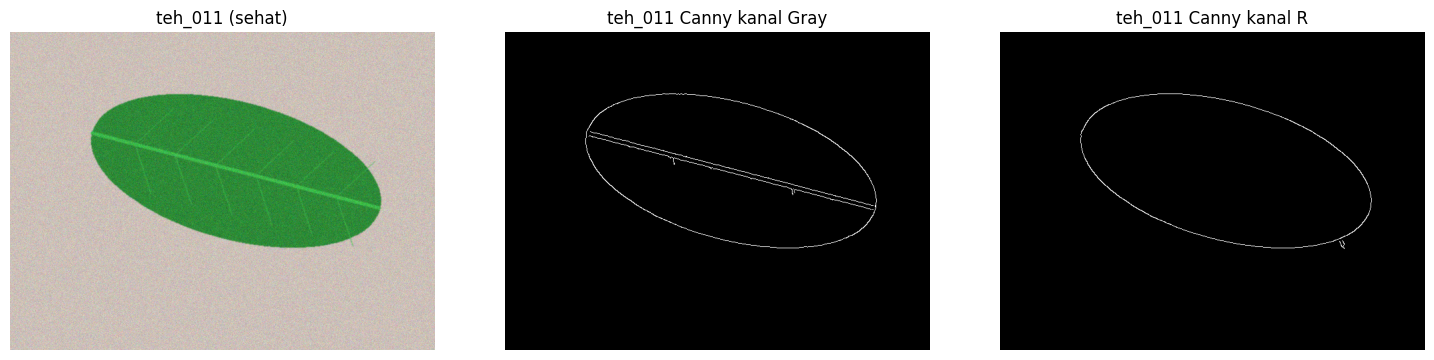

In [19]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal",
"piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
ukuran=(15, 3.6))